# Application : système de recommandation de films par SVD (Spark MLlib)

**Données :** MovieLens `ml-latest-small` (GroupLens) : 100 836 notes (0,5 à 5 étoiles),
610 utilisateurs, 9 742 films.
F. M. Harper & J. A. Konstan, *The MovieLens Datasets: History and Context*, ACM TiiS, 2015.

**Idée :** la matrice $R$ (utilisateurs × films) est presque vide (≈ 98 % de cases
manquantes). On suppose que les goûts dépendent de quelques **facteurs latents**
(action vs. drame, grand public vs. film d'auteur…). La SVD tronquée
$R \approx U_k \Sigma_k V_k^T$ :
- une ligne de $U_k \Sigma_k$ = profil d'un utilisateur dans l'espace des facteurs ;
- une ligne de $V_k$ = profil d'un film dans ce même espace ;
- leur produit scalaire = la note prédite.

**Pipeline :**
1. chargement avec les DataFrames Spark, découpage train / test ;
2. modèle de base : $\hat r_{ui} = \mu + b_u + b_i$ (moyenne + biais utilisateur + biais film) ;
3. matrice des **résidus** $r_{ui} - (\mu + b_u + b_i)$ → `IndexedRowMatrix` (RDD) ;
4. `computeSVD(k)` → $U, \Sigma, V$ ;
5. prédiction $\hat r_{ui} = \mu + b_u + b_i + (U_k \Sigma_k V_k^T)_{ui}$, évaluation RMSE ;
6. recommandations, films similaires, interprétation des facteurs.

In [1]:
import json
import os
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark.sql import functions as F

from spark_utils import cache_jvm, get_spark
from pyspark.mllib.linalg import Vectors
from pyspark.mllib.linalg.distributed import IndexedRow, IndexedRowMatrix

DATA_DIR = "data/ml-latest-small"
URL = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
if not os.path.exists(f"{DATA_DIR}/ratings.csv"):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(URL, "data/ml-latest-small.zip")
    zipfile.ZipFile("data/ml-latest-small.zip").extractall("data")

os.makedirs("figures", exist_ok=True)
spark = get_spark("SVD-recommandation-MovieLens")
sc = spark.sparkContext
RESULTS = {}

## 1. Chargement et exploration

In [2]:
ratings = spark.read.csv(f"{DATA_DIR}/ratings.csv", header=True, inferSchema=True).drop("timestamp")
movies = spark.read.csv(f"{DATA_DIR}/movies.csv", header=True, inferSchema=True, quote='"', escape='"')

n_users = ratings.select("userId").distinct().count()
n_movies = ratings.select("movieId").distinct().count()
n_ratings = ratings.count()
densite = n_ratings / (n_users * n_movies)
print(f"{n_ratings:,} notes, {n_users} utilisateurs, {n_movies:,} films")
print(f"Densité de la matrice : {densite:.2%}  (→ {1 - densite:.1%} de cases vides)")
RESULTS.update(n_ratings=n_ratings, n_users=n_users, n_movies=n_movies, densite=densite)
ratings.groupBy("rating").count().orderBy("rating").show()

100,836 notes, 610 utilisateurs, 9,724 films
Densité de la matrice : 1.70%  (→ 98.3% de cases vides)


+------+-----+
|rating|count|
+------+-----+
|   0.5| 1370|
|   1.0| 2811|
|   1.5| 1791|
|   2.0| 7551|
|   2.5| 5550|
|   3.0|20047|
|   3.5|13136|
|   4.0|26818|
|   4.5| 8551|
|   5.0|13211|
+------+-----+



On garde les films notés **au moins 10 fois** : en dessous, il n'y a pas assez
d'information pour estimer un profil latent fiable.

In [3]:
MIN_RATINGS = 10
pop = ratings.groupBy("movieId").count().filter(F.col("count") >= MIN_RATINGS)
ratings_f = ratings.join(pop.select("movieId"), "movieId")
print(f"Après filtrage : {ratings_f.count():,} notes, {pop.count():,} films")

# Index contigus 0..n-1 pour les lignes (utilisateurs) et colonnes (films) de la matrice
user_ids = sorted(r.userId for r in ratings_f.select("userId").distinct().collect())
movie_ids = sorted(r.movieId for r in ratings_f.select("movieId").distinct().collect())
u_index = {u: i for i, u in enumerate(user_ids)}
m_index = {m: j for j, m in enumerate(movie_ids)}
N_U, N_M = len(user_ids), len(movie_ids)
titles = dict(movies.select("movieId", "title").rdd.map(tuple).collect())
print(f"Matrice : {N_U} utilisateurs x {N_M:,} films")
RESULTS.update(min_ratings=MIN_RATINGS, n_movies_kept=N_M, n_ratings_kept=ratings_f.count())

Après filtrage : 81,116 notes, 2,269 films


Matrice : 610 utilisateurs x 2,269 films


## 2. Découpage train / test (80 / 20)
Le test sert à mesurer l'erreur sur des notes **que le modèle n'a jamais vues**.

In [4]:
train, test = ratings_f.randomSplit([0.8, 0.2], seed=42)
train.cache(); test.cache()
print(f"train : {train.count():,} notes   test : {test.count():,} notes")

train : 64,754 notes   test : 16,362 notes


## 3. Modèle de base : $\mu + b_u + b_i$
- $\mu$ : moyenne globale ;
- $b_u$ : l'utilisateur note-t-il plus sévèrement ou plus généreusement que la moyenne ?
- $b_i$ : le film est-il meilleur ou moins bon que la moyenne ?

Les biais sont « rétrécis » vers 0 ($\lambda = 10$) quand il y a peu de notes.

In [5]:
LAMBDA = 10.0
mu = train.agg(F.avg("rating")).first()[0]

b_u = (train.groupBy("userId")
       .agg((F.sum(F.col("rating") - mu) / (F.count("*") + LAMBDA)).alias("b_u")))
b_i = (train.join(b_u, "userId")
       .groupBy("movieId")
       .agg((F.sum(F.col("rating") - mu - F.col("b_u")) / (F.count("*") + LAMBDA)).alias("b_i")))

bu = np.zeros(N_U); bi = np.zeros(N_M)
for r in b_u.collect():
    bu[u_index[r.userId]] = r.b_u
for r in b_i.collect():
    bi[m_index[r.movieId]] = r.b_i
print(f"μ = {mu:.3f}")

μ = 3.574


## 4. Matrice des résidus → `IndexedRowMatrix` distribuée
Une ligne par utilisateur, stockée en **vecteur creux** (`SparseVector`) :
seules les notes connues sont stockées, les cases vides valent 0
(= « pas d'écart au modèle de base »).

In [6]:
bc_bu = sc.broadcast(bu); bc_bi = sc.broadcast(bi)
bc_ui = sc.broadcast(u_index); bc_mi = sc.broadcast(m_index)


def to_residual(row):
    u, m = bc_ui.value[row.userId], bc_mi.value[row.movieId]
    return u, (m, row.rating - mu - bc_bu.value[u] - bc_bi.value[m])


user_rows = (train.rdd.map(to_residual)
             .groupByKey()
             .map(lambda kv: IndexedRow(kv[0], Vectors.sparse(N_M, sorted(kv[1])))))

R = cache_jvm(IndexedRowMatrix(user_rows, numRows=N_U, numCols=N_M))
print("Matrice des résidus :", R.numRows(), "x", R.numCols())

Matrice des résidus : 610 x 2269


## 5. SVD tronquée avec Spark : `computeSVD(k)`

In [7]:
K_MAX = 50
svd = R.computeSVD(K_MAX, computeU=True)

s = svd.s.toArray()
V = svd.V.toArray()                                   # films x k (local)
U = np.zeros((N_U, K_MAX))                            # utilisateurs x k
for idx, vec in svd.U.rows.map(lambda r: (r.index, r.vector.toArray())).collect():
    U[idx] = vec
print("U :", U.shape, " Σ :", s.shape, " V :", V.shape)
print("10 premières valeurs singulières :", np.round(s[:10], 1))

U : (610, 50)  Σ : (50,)  V : (2269, 50)
10 premières valeurs singulières : [33.2 27.8 26.5 25.9 25.4 25.3 24.1 23.5 23.2 23. ]


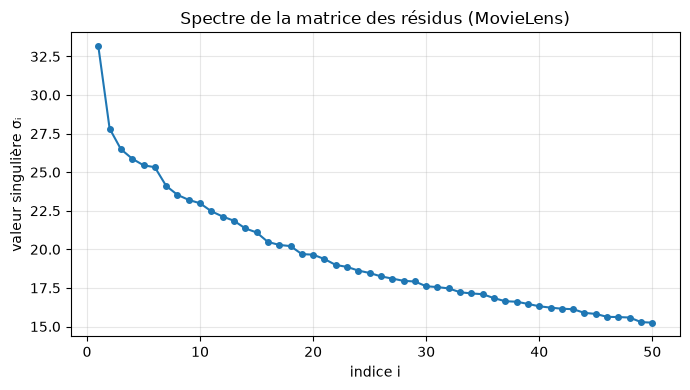

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, K_MAX + 1), s, "o-", ms=4)
ax.set_xlabel("indice i")
ax.set_ylabel("valeur singulière σᵢ")
ax.set_title("Spectre de la matrice des résidus (MovieLens)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/movielens_spectre.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Évaluation : RMSE sur le jeu de test en fonction de k
$\text{RMSE} = \sqrt{\frac{1}{|T|}\sum_{(u,i)\in T} (r_{ui} - \hat r_{ui})^2}$

Calcul distribué : $U\Sigma$ et $V$ sont diffusés (`broadcast`) aux workers,
chaque worker calcule l'erreur pour toutes les valeurs de k en un seul passage.

In [9]:
KS = [0, 1, 2, 3, 5, 8, 10, 15, 20, 30, 40, 50]   # k = 0 → modèle de base seul
bc_US = sc.broadcast(U * s); bc_V = sc.broadcast(V)


def sq_errors(row):
    u, m = bc_ui.value[row.userId], bc_mi.value[row.movieId]
    base = mu + bc_bu.value[u] + bc_bi.value[m]
    contrib = np.cumsum(bc_US.value[u] * bc_V.value[m])        # contribution cumulée des facteurs
    preds = np.array([base] + [base + contrib[k - 1] for k in KS[1:]])
    preds = np.clip(preds, 0.5, 5.0)
    return (preds - row.rating) ** 2


n_test = test.count()
mse = test.rdd.map(sq_errors).reduce(lambda a, b: a + b) / n_test
rmse_k = dict(zip(KS, np.sqrt(mse)))

# Références plus simples
rmse_global = np.sqrt(test.select(((F.col("rating") - mu) ** 2).alias("e")).agg(F.avg("e")).first()[0])
user_mean = train.groupBy("userId").agg(F.avg("rating").alias("um"))
rmse_user = np.sqrt(test.join(user_mean, "userId")
                    .select(((F.col("rating") - F.col("um")) ** 2).alias("e")).agg(F.avg("e")).first()[0])

best_k = min(KS[1:], key=lambda k: rmse_k[k])
print(f"Moyenne globale          : RMSE = {rmse_global:.4f}")
print(f"Moyenne de l'utilisateur : RMSE = {rmse_user:.4f}")
print(f"μ + b_u + b_i (k = 0)    : RMSE = {rmse_k[0]:.4f}")
for k in KS[1:]:
    print(f"  + SVD k = {k:<3}           : RMSE = {rmse_k[k]:.4f}{'   ← meilleur' if k == best_k else ''}")
RESULTS.update(rmse_global=rmse_global, rmse_user=rmse_user,
               rmse_k={int(k): float(v) for k, v in rmse_k.items()}, best_k=int(best_k))

Moyenne globale          : RMSE = 1.0208
Moyenne de l'utilisateur : RMSE = 0.9354
μ + b_u + b_i (k = 0)    : RMSE = 0.8657
  + SVD k = 1             : RMSE = 0.8590
  + SVD k = 2             : RMSE = 0.8572
  + SVD k = 3             : RMSE = 0.8547
  + SVD k = 5             : RMSE = 0.8532
  + SVD k = 8             : RMSE = 0.8522
  + SVD k = 10            : RMSE = 0.8511   ← meilleur
  + SVD k = 15            : RMSE = 0.8527
  + SVD k = 20            : RMSE = 0.8529
  + SVD k = 30            : RMSE = 0.8538
  + SVD k = 40            : RMSE = 0.8554
  + SVD k = 50            : RMSE = 0.8565


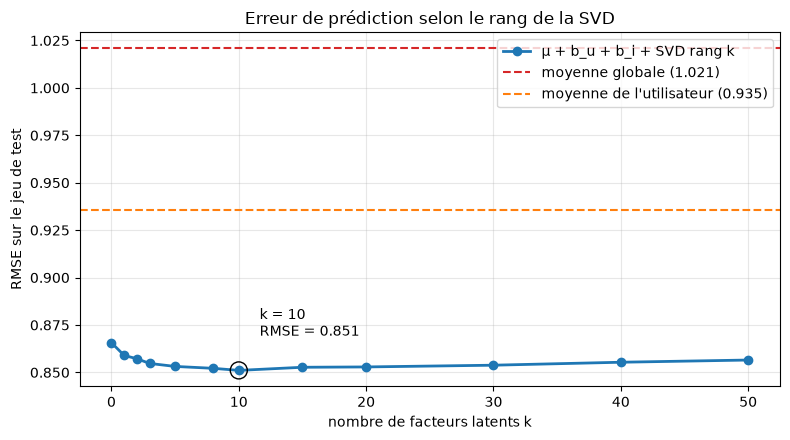

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(KS, [rmse_k[k] for k in KS], "o-", lw=2, label="μ + b_u + b_i + SVD rang k")
ax.axhline(rmse_global, color="tab:red", ls="--", label=f"moyenne globale ({rmse_global:.3f})")
ax.axhline(rmse_user, color="tab:orange", ls="--", label=f"moyenne de l'utilisateur ({rmse_user:.3f})")
ax.scatter([best_k], [rmse_k[best_k]], s=150, facecolors="none", edgecolors="k", zorder=5)
ax.annotate(f"k = {best_k}\nRMSE = {rmse_k[best_k]:.3f}", (best_k, rmse_k[best_k]),
            xytext=(15, 25), textcoords="offset points")
ax.set_xlabel("nombre de facteurs latents k")
ax.set_ylabel("RMSE sur le jeu de test")
ax.set_title("Erreur de prédiction selon le rang de la SVD")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/movielens_rmse.png", dpi=150, bbox_inches="tight")
plt.show()

**Lecture :** les premiers facteurs améliorent la prédiction ; au-delà, la SVD
commence à « apprendre le bruit » (les cases vides valent 0) et l'erreur remonte :
c'est du **sur-apprentissage**. k joue le rôle d'un paramètre de régularisation.

## 7. Recommandations pour un utilisateur
Score de tous les films non vus : $\hat r_{ui} = \mu + b_u + b_i + (U_k\Sigma_k V_k^T)_{ui}$,
puis on garde les 10 meilleurs.

In [11]:
K = best_k


def predict_user(u):
    return mu + bu[u] + bi + (U[u, :K] * s[:K]) @ V[:, :K].T


def recommend(user_id, n=10):
    u = u_index[user_id]
    seen = {r.movieId for r in train.filter(F.col("userId") == user_id).select("movieId").collect()}
    scores = predict_user(u)
    order = np.argsort(-scores)
    recs = [(titles[movie_ids[j]], scores[j]) for j in order if movie_ids[j] not in seen][:n]
    return recs


USER_ID = 414
top_user = (train.filter(F.col("userId") == USER_ID).orderBy(F.desc("rating"), "movieId")
            .limit(10).toPandas())
top_user["title"] = top_user.movieId.map(titles)
print(f"Utilisateur {USER_ID} : ses films les mieux notés")
print(top_user[["title", "rating"]].to_string(index=False))
print(f"\nRecommandations SVD (k = {K}) :")
recs = recommend(USER_ID)
for t, sc_ in recs:
    print(f"  {sc_:.2f}  {t}")
RESULTS["reco"] = {"user": USER_ID,
                   "aimes": top_user[["title", "rating"]].values.tolist(),
                   "recos": [[t, float(v)] for t, v in recs]}

Utilisateur 414 : ses films les mieux notés
                                    title  rating
           American President, The (1995)     5.0
                              Babe (1995)     5.0
               Usual Suspects, The (1995)     5.0
                   Beautiful Girls (1996)     5.0
                       Taxi Driver (1976)     5.0
                           Rob Roy (1995)     5.0
                            Clerks (1994)     5.0
Star Wars: Episode IV - A New Hope (1977)     5.0
               Legends of the Fall (1994)     5.0
                Once Were Warriors (1994)     5.0

Recommandations SVD (k = 10) :
  4.81  Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981)
  4.74  Forrest Gump (1994)
  4.66  Apocalypse Now (1979)
  4.60  Silence of the Lambs, The (1991)
  4.43  Big (1988)
  4.41  Terminator 2: Judgment Day (1991)
  4.37  Trainspotting (1996)
  4.29  Cool Hand Luke (1967)
  4.29  Chinatown (1974)
  4.28  Gladiator (2000)


## 8. Films similaires dans l'espace latent
Chaque film est un vecteur de $V_k \Sigma_k$. Deux films sont proches si les **mêmes
utilisateurs** les apprécient de la même façon → similarité cosinus.
Aucune information sur le genre ou le contenu n'est utilisée : tout vient des notes.
(On ne propose que des films notés au moins 30 fois, pour des voisins fiables.)

In [12]:
K_SIM = 20
counts = dict(pop.rdd.map(tuple).collect())
candidats = np.array([counts[mid] >= 30 for mid in movie_ids])
item_vec = V[:, :K_SIM] * s[:K_SIM]
item_vec_n = item_vec / np.linalg.norm(item_vec, axis=1, keepdims=True)
title_to_j = {titles[mid]: j for j, mid in enumerate(movie_ids)}


def similar(title, n=5):
    j = title_to_j[title]
    sims = item_vec_n @ item_vec_n[j]
    order = [i for i in np.argsort(-sims) if i != j and candidats[i]][:n]
    return [(titles[movie_ids[i]], float(sims[i])) for i in order]


RESULTS["similaires"] = {}
for q in ["Toy Story (1995)", "Matrix, The (1999)", "Lord of the Rings: The Fellowship of the Ring, The (2001)", "Notebook, The (2004)"]:
    sims = similar(q)
    RESULTS["similaires"][q] = sims
    print(f"\n{q}")
    for t, v in sims:
        print(f"   {v:.2f}  {t}")


Toy Story (1995)
   0.69  Aladdin (1992)
   0.68  Lion King, The (1994)
   0.66  Billy Elliot (2000)
   0.63  Kiss Kiss Bang Bang (2005)
   0.60  Great Escape, The (1963)

Matrix, The (1999)
   0.62  Saving Private Ryan (1998)
   0.62  Jurassic Park (1993)
   0.60  Star Wars: Episode VI - Return of the Jedi (1983)
   0.58  Aliens (1986)
   0.57  Planet of the Apes (1968)

Lord of the Rings: The Fellowship of the Ring, The (2001)
   0.91  Lord of the Rings: The Two Towers, The (2002)
   0.75  Lord of the Rings: The Return of the King, The (2003)
   0.60  Indiana Jones and the Last Crusade (1989)
   0.57  Iron Giant, The (1999)
   0.57  Dark Knight Rises, The (2012)

Notebook, The (2004)
   0.80  (500) Days of Summer (2009)
   0.78  Brokeback Mountain (2005)
   0.67  Breakfast at Tiffany's (1961)
   0.63  When Harry Met Sally... (1989)
   0.61  Black Swan (2010)


## 9. Que représentent les facteurs latents ?
On regarde, parmi les films populaires (≥ 50 notes), ceux qui ont les valeurs
extrêmes sur les deux premiers axes de $V$.

In [13]:
popular = [j for j, mid in enumerate(movie_ids) if counts[mid] >= 50]
RESULTS["axes"] = {}
for ax_i in range(2):
    order = sorted(popular, key=lambda j: V[j, ax_i])
    neg = [titles[movie_ids[j]] for j in order[:6]]
    posi = [titles[movie_ids[j]] for j in order[-6:][::-1]]
    RESULTS["axes"][f"axe{ax_i + 1}"] = {"negatif": neg, "positif": posi}
    print(f"\nAxe {ax_i + 1}  (−) : {neg}")
    print(f"Axe {ax_i + 1}  (+) : {posi}")


Axe 1  (−) : ['Broken Arrow (1996)', "Harry Potter and the Sorcerer's Stone (a.k.a. Harry Potter and the Philosopher's Stone) (2001)", "Pirates of the Caribbean: At World's End (2007)", 'Twister (1996)', 'Batman Forever (1995)', 'Net, The (1995)']
Axe 1  (+) : ['Pulp Fiction (1994)', 'Star Wars: Episode IV - A New Hope (1977)', '2001: A Space Odyssey (1968)', 'Star Wars: Episode V - The Empire Strikes Back (1980)', 'Big Lebowski, The (1998)', 'Godfather, The (1972)']

Axe 2  (−) : ['Four Weddings and a Funeral (1994)', 'Pinocchio (1940)', 'Little Mermaid, The (1989)', 'Fargo (1996)', '2001: A Space Odyssey (1968)', 'Wizard of Oz, The (1939)']
Axe 2  (+) : ['Matrix, The (1999)', 'Spider-Man (2002)', 'X-Men (2000)', 'Star Wars: Episode VI - Return of the Jedi (1983)', 'GoldenEye (1995)', 'Pirates of the Caribbean: The Curse of the Black Pearl (2003)']


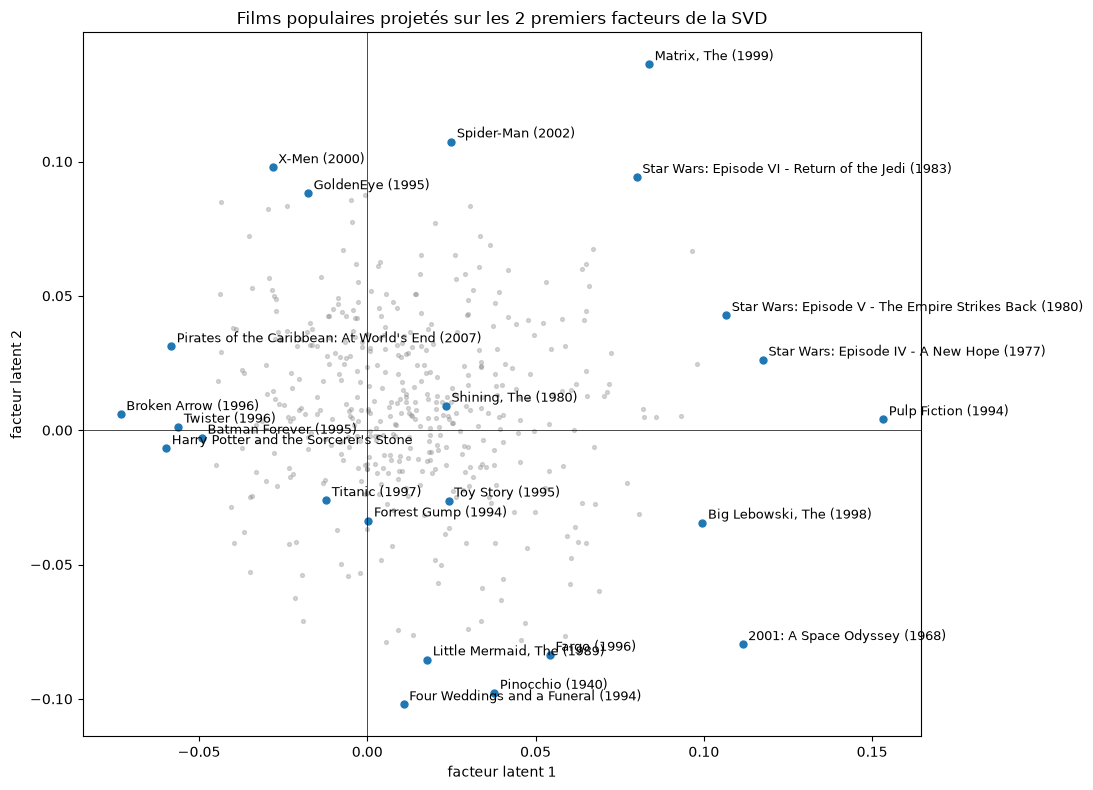

In [14]:
fig, ax = plt.subplots(figsize=(11, 8))
P = V[popular, :2]
ax.scatter(P[:, 0], P[:, 1], s=8, alpha=0.3, color="grey")
annot = set()
for ax_i in range(2):
    order = sorted(popular, key=lambda j: V[j, ax_i])
    annot.update(order[:5] + order[-5:])
for q in ["Toy Story (1995)", "Matrix, The (1999)", "Shining, The (1980)", "Titanic (1997)",
          "Pulp Fiction (1994)", "Forrest Gump (1994)"]:
    annot.add(title_to_j[q])
for j in annot:
    ax.scatter(V[j, 0], V[j, 1], s=25, color="tab:blue")
    court = titles[movie_ids[j]].split(" (a.k.a.")[0].split(" (Harry Potter and")[0]
    ax.annotate(court, (V[j, 0], V[j, 1]), fontsize=9,
                xytext=(4, 3), textcoords="offset points")
ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
ax.set_xlabel("facteur latent 1")
ax.set_ylabel("facteur latent 2")
ax.set_title("Films populaires projetés sur les 2 premiers facteurs de la SVD")
plt.tight_layout()
plt.savefig("figures/movielens_facteurs_2d.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
with open("figures/resultats_movielens.json", "w", encoding="utf-8") as f:
    json.dump(RESULTS, f, ensure_ascii=False, indent=2, default=float)
spark.stop()